# Predicting Term Deposit Prediction using Machine Learning

## Introduction:

Banks all around the world use direct marketing campaigns to contact their customers and promote financial products such as term deposits and etc. But, contacting every customer requires a lot of resources so a machine learning model can be used to predict whether a customer will subscribe to a term deposit. By identifying customers who are more likely to subscribe for term deposit, the bank could focus its marketing efforts and resources on more promising customers.

This project tells if a customer and campaign information can be used to predict whether a customer will go for term deposit. The problem is formulated as a binary classification task, where the target variable 'y' tells whether the customer subscribed (yes) or did not subscribe (no).

The aim of this project is to develop an end-to-end machine learning pipeline that consists of data exploration,data preprocessing, model training, hyperparameter tuning and evaluation on an unseen test set.

The results will then be interpreted from a business perspective, including the potential strengths and limitations of the proposed solution.

### Data Collection and Dataset Description:

The dataset used in this project is the Bank Marketing dataset, obtained
from Kaggle:

https://www.kaggle.com/datasets/ruthgn/bank-marketing-data-set

The dataset (Kaggle) contains information about customers and the characteristics of a bank's direct marketing campaign. The target variable is `y`, which indicates whether the customer subscribed to a term deposit or not.

The target variable `y` contains two classes: `yes` and `no`. Therefore, the prediction problem is formulated as binary classification.

The dataset is suitable for this project because it contains a clearly defined target variable and a mixture of numerical and categorical features. 

In [82]:
import pandas as pd
import matplotlib.pyplot as plt

marketing = pd.read_csv(r"D:\Docs\MSc Data Science, AI and Digital Business\Intro to AI and ML\bank-direct-marketing-campaigns.csv")
marketing.shape

(41188, 20)

The output confirms that the dataset has loaded successfully and it has 41188 rows and 20 columns.

## Data Exploration:

In this step, we will check missing values, duplicated values, column names etc.

In [87]:
marketing.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [89]:
marketing.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [91]:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  campaign        41188 non-null  int64  
 11  pdays           41188 non-null  int64  
 12  previous        41188 non-null  int64  
 13  poutcome        41188 non-null  object 
 14  emp.var.rate    41188 non-null  float64
 15  cons.price.idx  41188 non-null  float64
 16  cons.conf.idx   41188 non-null  float64
 17  euribor3m       41188 non-null 

In [93]:
marketing.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

.isnull() returns the missing values in each column. In our case, we do not have any missing values, therefore, no missing-value imputation is required before modelling.

In [96]:
marketing.duplicated().sum()

1784

In out case, the dataset contains 1,784 duplicate rows.

In [99]:
marketing['y'].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

This is important step for our task because `y` is our target column. The target variable `y` contains two classes: `no` and `yes`. There are 36,548 customers who did not subscribe to a term deposit and 4,640 who did subscribe.

This imbalance means that accuracy alone may not provide a reliable assessment of model performance. Precision, recall, F1-score and ROC-AUC will therefore also be considered during model evaluation.

In [102]:
marketing.describe()

,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


.describe() function returns the numerical statistics of the dataset. The numerical variables have different ranges and distributions.

In [105]:
marketing.select_dtypes(include='object').nunique()

job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3
y               2
dtype: int64

The nunique() function returns the unique values of each column we already enough data for numerical columns so I have run this command only on categorical column by selecting the datatype `object`. The `job` variable has 12 categories, while `education` has 8 and `month` has 10. The remaining categorical variables contain between 2 and 5 categories. These variables will require categorical encoding before they can be used by the machine learning models.

In [108]:
marketing.groupby('y')['age'].mean()

y
no     39.911185
yes    40.913147
Name: age, dtype: float64

In [110]:
marketing.groupby('job')['y'].apply(lambda x: (x == 'yes').mean()).sort_values()

job
blue-collar      0.068943
services         0.081381
entrepreneur     0.085165
housemaid        0.100000
self-employed    0.104856
technician       0.108260
unknown          0.112121
management       0.112175
admin.           0.129726
unemployed       0.142012
retired          0.252326
student          0.314286
Name: y, dtype: float64

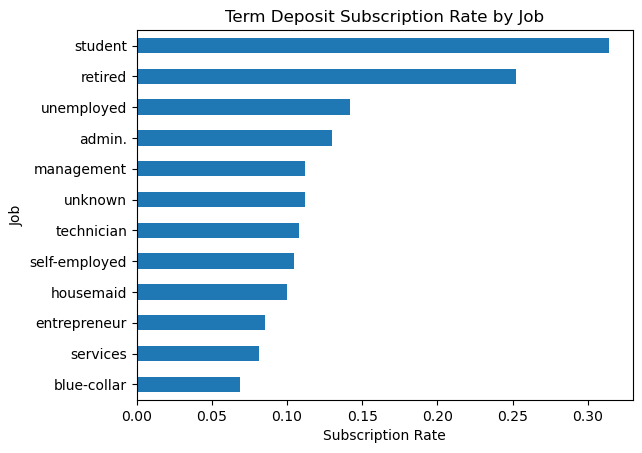

In [112]:
job_rate = marketing.groupby('job')['y'].apply(lambda x: (x == 'yes').mean()).sort_values()

job_rate.plot(kind='barh')
plt.title('Term Deposit Subscription Rate by Job')
plt.xlabel('Subscription Rate')
plt.ylabel('Job')
plt.show()

This is an important finding because as we can see from chart that the subscription by job varies signifcally. Students and retired customers have higher subscription rates than other groups, while blue-collar and services customers have lower rates.

## Data Preprocessing:

In [116]:
marketing = marketing.drop_duplicates()

print("Dataset shape after removing duplicates:", marketing.shape)

Dataset shape after removing duplicates: (39404, 20)


Duplicate rows were removed to prevent repeated observations from having
an unnecessary influence on the machine learning models.

In [119]:
X = marketing.drop('y', axis=1)
y = marketing['y'].map({'no': 0, 'yes': 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (39404, 19)
Target shape: (39404,)


Now we need to separate:

X → input features used to make predictions

y → target variable we want to predict

In [122]:
from sklearn.model_selection import train_test_split     #(Scikit-learn)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (27582, 19)
Test set: (11822, 19)


I have split the dataset into training and test with 70% and 30% division for training and testing respectively. I have used stratify to preserve the proportion of both sets.

In [125]:
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


Splitting the numerical and categorical columns.

In [128]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


The dataset contains both numerical and categorical variables, so different
preprocessing methods are required for each type. The numerical features are
standardised using `StandardScaler` so that variables with larger numerical
ranges do not disproportionately influence the models. The categorical
features are transformed using one-hot encoding, allowing categorical
information to be represented numerically without assuming an artificial
ordering between categories.

A `ColumnTransformer` is used to apply the appropriate transformation to
each group of features. This creates a consistent preprocessing process that
can later be combined with the machine learning models in a pipeline.

## Model Training

### Logistic Regression Model

In [133]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


Logistic Regression is selected as the first classification model because
the target variable contains two possible outcomes: subscription (`yes`)
or non-subscription (`no`).

The preprocessing steps are combined with the model in a single pipeline.
The `class_weight='balanced'` option is used because the target variable
is imbalanced, giving greater importance to the minority class in the dataset.

### Training Logistic Regression Model

In [136]:
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


The Logistic Regression pipeline is trained using only the training
dataset. During this process, the preprocessing transformations are fitted
to the training data and the model learns relationships between the input
features and the target variable.

### Predictions

In [141]:
y_pred = logistic_pipeline.predict(X_test)

print("Predictions generated:", len(y_pred))

Predictions generated: 11822


After training, the model is used to predict the target variable for the
unseen test dataset as the test data was not used during model training.

### Model Evaluation

In [145]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy Score:", round(accuracy_score(y_test, y_pred), 2))
print("Precision Score:", round(precision_score(y_test, y_pred), 2))
print("Recall Score:", round(recall_score(y_test, y_pred), 2))
print("F1-score:", round(f1_score(y_test, y_pred), 2))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob), 2))

Accuracy Score: 0.83
Precision Score: 0.36
Recall Score: 0.65
F1-score: 0.47
ROC-AUC Score: 0.8


The Logistic Regression model achieved an accuracy of 0.83 and a
ROC-AUC of 0.8 on the unseen test set. The recall of 0.65 indicates
that the model identified approximately 65% of the customers who
subscribed to a term deposit.

However, the precision was 0.36, meaning that a relatively large
proportion of customers predicted as subscribers did not actually
subscribe. The F1-score of 0.47 reflects the balance between precision
and recall. These results provide a baseline for comparison with a
second classification model.

### Random Forest Model

Random Forest is selected as a second classification model because it can capture non-linear relationships between features and the target.

In [150]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

print("Random Forest pipeline created.")

Random Forest pipeline created.


### Training Random Forest Model

In [153]:
random_forest_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


The Random Forest pipeline is fitted using the training data. The model
learns patterns from the preprocessed customer and campaign features
while the test data remains completely unseen.

### Predictions

In [156]:
y_pred_rf = random_forest_pipeline.predict(X_test)

print("Random Forest predictions generated:", len(y_pred_rf))

Random Forest predictions generated: 11822


The trained Random Forest model is used to generate predictions for the unseen test dataset. These predictions will then be evaluated using the same metrics used for Logistic Regression which will make a fair comparison between the two models.

### Evaluation

In [159]:
y_prob_rf = random_forest_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy Score:", round(accuracy_score(y_test, y_pred_rf), 2))
print("Precision Score:", round(precision_score(y_test, y_pred_rf), 2))
print("Recall Score:", round(recall_score(y_test, y_pred_rf), 2))
print("F1-score:", round(f1_score(y_test, y_pred_rf), 2))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob_rf), 2))

Accuracy Score: 0.89
Precision Score: 0.54
Recall Score: 0.28
F1-score: 0.37
ROC-AUC Score: 0.77


The Random Forest model achieved an accuracy of 0.89 and a precision of
0.54 on the unseen test set. Its recall was 0.28, meaning that the model
identified approximately 28% of customers who actually subscribed to a
term deposit. The F1-score was 0.37, while the ROC-AUC was 0.77.

Although the model achieved higher accuracy and precision than the
Logistic Regression model, its recall was considerably lower. This shows
that the Random Forest model identifies fewer of the actual subscribers.
Therefore, accuracy alone does not provide enough information to assess
the usefulness of the model for this business problem.

### Models Comparison

The two models show different performance characteristics. Random Forest
achieved higher accuracy and precision, while Logistic Regression achieved
higher recall, F1-score and ROC-AUC. The higher recall of Logistic Regression
means that it identified a larger proportion of the customers who actually
subscribed to a term deposit.

Because the business objective is to identify potential subscribers for
marketing, recall is an important consideration. However, precision is
also relevant because contacting customers who are unlikely to subscribe
can use additional marketing resources. Therefore, the model selection
should consider the trade-off between these metrics rather than accuracy
alone.

## Hyperparameter Tuning

### Logistic Regression

Grid search is used to investigate different values of the Logistic Regression regularisation parameter `C`.

In [166]:
from sklearn.model_selection import GridSearchCV

logistic_parameters = {
    'model__C': [0.01, 0.1, 1, 10]
}

logistic_grid = GridSearchCV(
    logistic_pipeline,
    param_grid=logistic_parameters,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

print("Most suitable parameters:", logistic_grid.best_params_)
print("Best cross-validation F1-score:", round(logistic_grid.best_score_, 3))

Most suitable parameters: {'model__C': 1}
Best cross-validation F1-score: 0.448


The grid search identified `C = 1` as the best regularisation parameter
for Logistic Regression. This setting achieved a cross-validation F1-score
of 0.448 across the training data. The result indicates that, among the
tested values, `C = 1` provided the best balance between precision and
recall according to the selected F1-score metric.

### Random Forest

Grid search is used to test different Random Forest configurations. The number of trees (`n_estimators`) and the maximum tree depth (`max_depth`) are varied.

In [170]:
rf_parameters = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [10, 20]
}

rf_grid = GridSearchCV(
    random_forest_pipeline,
    param_grid=rf_parameters,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Most suitable parameters:", rf_grid.best_params_)
print("Best cross-validation F1-score:", round(rf_grid.best_score_, 3))

Most suitable parameters: {'model__max_depth': 10, 'model__n_estimators': 100}
Best cross-validation F1-score: 0.484


The grid search identified a maximum tree depth of 10 and 100 trees as
the best configuration among the tested combinations. This configuration
achieved a cross-validation F1-score of 0.484.

The tuned Random Forest achieved a higher cross-validation F1-score than
the tuned Logistic Regression result of 0.448.

## Model Assessment

### Tuned Logistic Regression Test Evaluation



In [174]:
y_pred_log_tuned = logistic_grid.predict(X_test)
y_prob_log_tuned = logistic_grid.predict_proba(X_test)[:, 1]

print("Accuracy Score:", round(accuracy_score(y_test, y_pred_log_tuned), 2))
print("Precision Score:", round(precision_score(y_test, y_pred_log_tuned), 2))
print("Recall Score:", round(recall_score(y_test, y_pred_log_tuned), 2))
print("F1-score:", round(f1_score(y_test, y_pred_log_tuned), 2))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_log_tuned), 2))

Accuracy Score: 0.83
Precision Score: 0.36
Recall Score: 0.65
F1-score: 0.47
ROC-AUC: 0.8


The tuned Logistic Regression model achieved an accuracy score of 0.83, precision score of 0.36, recall score of 0.65, F1-score of 0.47 and ROC-AUC of
0.8 on the test set. These results are identical to the initial Logistic Regression model because the selected value of `C = 1` was already the model's original setting.

Therefore, hyperparameter tuning did not produce a measurable change in the test-set performance for Logistic Regression.

### Tuned Random Forest Test Evaluation

In [177]:
y_pred_rf_tuned = rf_grid.predict(X_test)
y_prob_rf_tuned = rf_grid.predict_proba(X_test)[:, 1]

print("Accuracy Score:", round(accuracy_score(y_test, y_pred_rf_tuned), 2))
print("Precision Score:", round(precision_score(y_test, y_pred_rf_tuned), 2))
print("Recall Score:", round(recall_score(y_test, y_pred_rf_tuned), 2))
print("F1-score:", round(f1_score(y_test, y_pred_rf_tuned), 2))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf_tuned), 2))

Accuracy Score: 0.86
Precision Score: 0.42
Recall Score: 0.62
F1-score: 0.5
ROC-AUC: 0.81


### Models Comparison after Hyperparameter Tuning

The tuned Random Forest achieved higher accuracy, precision, F1-score and
ROC-AUC than the tuned Logistic Regression model on the unseen test set.
Its recall was slightly lower than Logistic Regression (0.618 compared
with 0.646).

The tuned Random Forest therefore provides a different balance between
precision and recall. Its F1-score of 0.502 and ROC-AUC of 0.805 indicate
that the tuned model improved compared with the original Random Forest.
The results show that model performance depends on the evaluation metric,
particularly when the target variable is imbalanced.

### Confusion Matrix

A confusion matrix is used to examine the types of predictions made by
the tuned Random Forest model. It shows the number of correctly and
incorrectly classified customers for both the non-subscription and
subscription classes.

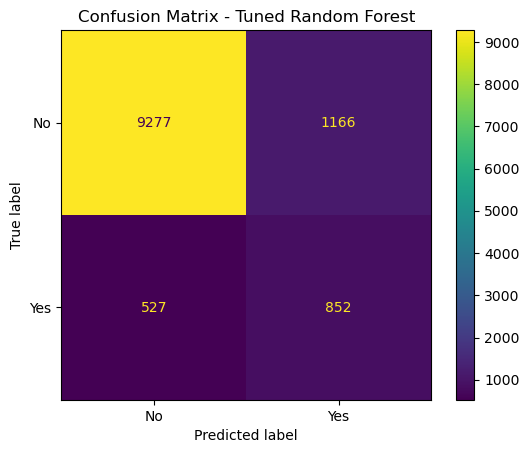

In [183]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf_tuned,
    display_labels=['No', 'Yes']
)

plt.title('Confusion Matrix - Tuned Random Forest')
plt.show()

The tuned Random Forest correctly classified 9,277 customers who did not
subscribe and 852 customers who subscribed. The model incorrectly
classified 1,166 non-subscribers as subscribers and failed to identify 527
customers who actually subscribed.

The 852 true positives show that the model can identify a substantial
proportion of subscribers. However, the 527 false negatives indicate that
some potential subscribers would still be missed. The 1,166 false
positives also show that some customers predicted as potential subscribers
would not actually subscribe.

###  Feature Importance and Explainability

Feature importance is examined to identify which transformed variables
contribute most to the Random Forest predictions. This provides a degree
of model explainability and helps identify customer or campaign
characteristics that may contain useful information for predicting term
deposit subscription.

In [187]:
feature_names = rf_grid.best_estimator_['preprocessing'].get_feature_names_out()
importances = rf_grid.best_estimator_['model'].feature_importances_

feature_importance = (
    pd.Series(importances, index=feature_names)
    .sort_values(ascending=False)
)

print(feature_importance.head(10))

num__nr.employed          0.166796
num__euribor3m            0.164955
num__emp.var.rate         0.126244
num__cons.conf.idx        0.068571
num__pdays                0.046078
cat__poutcome_success     0.037794
num__cons.price.idx       0.036881
num__age                  0.036757
cat__contact_telephone    0.025307
cat__contact_cellular     0.022873
dtype: float64


The feature importance results show that nr.employed, euribor3m and emp.var.rate are among the most informative features used by the Random Forest model. Other informative variables include cons.conf.idx, pdays, poutcome_success, cons.price.idx and age.

The results indicate that both economic indicators and customer or campaign-related characteristics contribute to the model's predictions. However,
feature importance represents the usefulness of variables for the model's predictions and should not be interpreted as evidence of causal relationships.

## Final Discussion

### Strengths and Limitation

The project uses an end-to-end pipeline that combines data preprocessing,
model training, hyperparameter tuning and evaluation on an unseen test
set. Using both Logistic Regression and Random Forest provided a
comparison between a simpler linear model and a non-linear tree-based
model. The use of multiple evaluation metrics was also important because
the target variable was imbalanced.

A limitation is that the dataset contains an imbalanced target, meaning
that predicting the minority subscription class remains challenging.
Although class weighting was used, the models still produced false
positives and false negatives. In addition, the Random Forest feature
importance results indicate which variables were useful for prediction but
do not establish causal relationships. The dataset represents a specific
marketing campaign context, so further validation would be required before
using the model in a different banking environment.

### Business Implications

The results suggest that machine learning could support the bank's
marketing campaign by helping identify customers who are more likely to
subscribe to a term deposit. The tuned Random Forest identified 852 actual
subscribers in the test set, while 527 subscribers were not identified by
the model.

The precision of 0.422 indicates that not every customer identified as a
potential subscriber would actually subscribe. Therefore, the model should
be viewed as a decision-support tool rather than a replacement for the
bank's existing marketing process.

The model could potentially help prioritise customers for marketing
contact, allowing campaign resources to be focused on customers predicted
to have a higher likelihood of subscription. However, the bank would need
to consider the cost of false positives and false negatives before using
the model operationally.

### Data Driven Recommmendations

The bank could use the model to prioritise customers for marketing contact
rather than treating all customers equally. The model's predictions could
be used to create a shortlist of customers with a higher predicted
likelihood of subscription.

The bank should also monitor precision and recall when using the model.
Increasing the number of identified potential subscribers may result in
more false-positive contacts, while focusing more strongly on precision
could cause some potential subscribers to be missed. Therefore, the
classification threshold could be adjusted according to the relative
costs of these outcomes.

The feature importance analysis suggests that economic indicators and
previous campaign information contain useful predictive information.
These variables could therefore be monitored when developing future
campaign strategies, while recognising that model importance does not
demonstrate causation.

### Deployment Considerations

Before deployment, the model should be validated using more recent
campaign data to determine whether its performance remains consistent
over time. The bank should also monitor precision, recall and the types
of errors produced by the model after deployment.

The model could be integrated into the bank's marketing system to provide
a predicted likelihood of subscription for eligible customers. Marketing
staff could then use these predictions as one input when prioritising
customers for contact.

Any operational deployment should also include appropriate data
protection, security and monitoring procedures. Model performance should
be reviewed regularly because customer behaviour and economic conditions
may change over time.

### Conclusion

This project developed an end-to-end machine learning pipeline to predict whether customers would subscribe to a term deposit. The dataset was explored and preprocessed before Logistic Regression and Random Forest models were trained and tuned using cross-validation.

On the unseen test set, the tuned Random Forest achieved an accuracy of 0.88, F1-score of 0.50 and ROC-AUC of 0.81, while Logistic Regression
achieved an accuracy of 0.83, F1-score of 0.47 and ROC-AUC of 0.8. The results demonstrate that machine learning can provide useful information for prioritising potential customers, although prediction errors and the imbalanced target remain important limitations.

Further validation using new campaign data would be required before the
model could be considered for operational use.

## 9. References

Kaggle  *Bank Marketing Data Set*. Available at:
https://www.kaggle.com/datasets/ruthgn/bank-marketing-data-set
(Accessed: 06 September 2026).

Scikit-learn  *Scikit-learn: Machine Learning in Python*.
Available at: https://scikit-learn.org/
(Accessed: 15 September 2026).

Pandas (2026) *pandas documentation*. Available at:
https://pandas.pydata.org/docs/
(Accessed: 15 September 2026).

Matplotlib (2026) Matplotlib documentation. Available at:
https://matplotlib.org/stable/
(Accessed: 15 September 2026).